# Process NIDQ Auxiliary Data

End-to-end workflow for loading, labelling, and extracting events from NIDQ auxiliary channels recorded with SpikeGLX.

**Covers:**
- Loading raw NIDQ data via `load_nidq()`
- Interactive channel labelling with `NidqChannelConfigWidget`
- Reloading with voltage gain calibration and saved channel names
- Extracting events and intervals from digital channels
- Extracting events and intervals from analog channels
- Tracking instantaneous pulse frequency
- Characterising pulses and detecting bouts
- Batch event extraction via `extract_nidq_events()`

**Requirements:** Place a copy of this notebook in (or point `data_dir` at) your recording session directory. A `session_config.json` will be created automatically if not present.

In [ ]:
%matplotlib widget

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Session management
from mimo_pack.core import Session
from mimo_pack.widgets import SessionInitializer, NidqChannelConfigWidget

# NIDQ file I/O
from mimo_pack.fileio.nidq import load_nidq
from mimo_pack.fileio.spikeglx import dclut_from_meta

# Generic signal preprocessing
from mimo_pack.preprocess.signal import (
    binarize,
    digital_to_events,
    digital_to_intervals,
    analog_to_events,
    analog_to_intervals,
    track_pulse_frequency,
    pulse_stats,
    detect_bouts,
)

# NIDQ-specific event dispatch
from mimo_pack.preprocess.nidq import extract_nidq_events

# Dimension / attribute constants
from mimo_pack.consts import DIM_TIME, DIM_CHAN, ATTR_FS, ATTR_UNITS

print("Imports OK")

Imports OK


## 0. Session Initialisation

1. Use the `SessionInitializer` widget to select the folder containing your SpikeGLX recording files.
2. The widget creates a default `session_config.json` if one does not already exist, then loads the `Session`.
3. After clicking **Load Session**, run the next cell to discover NIDQ files.


In [2]:
initializer = SessionInitializer()
initializer.display()

# After clicking 'Load Session' in the widget above, run the next cell to discover NIDQ files.


In [4]:
sess = initializer.session
print(f"Session dir  : {sess.dir}")
print(f"Config path  : {sess.config_path}")

# Locate NIDQ binary files, then resolve to dclut JSON paths
nidq_bin_files = sess.find_files('nidq_pattern')
print(f"\nNIDQ bin files ({len(nidq_bin_files)}):")
for f in nidq_bin_files:
    print(f"  {f}")

nidq_files = [sess.get_dclut_path(str(f)) for f in nidq_bin_files]
print(f"\nNIDQ dclut paths:")
for f in nidq_files:
    print(f"  {f}")


Session dir  : D:\SortingTemp\24-05-31_DH23_A1-IC_g0
Config path  : D:\SortingTemp\24-05-31_DH23_A1-IC_g0\session_config.json

NIDQ bin files (1):
  D:\SortingTemp\24-05-31_DH23_A1-IC_g0\24-05-31_DH23_A1-IC_g0_t0.nidq.bin

NIDQ dclut paths:
  D:\SortingTemp\24-05-31_DH23_A1-IC_g0\24-05-31_DH23_A1-IC_g0_t0.nidq_dclut.json


## 1. Load NIDQ Data

- `load_nidq()` reads a `*.nidq_dclut.json` file and returns an `xr.DataArray` with dims `(time, channel)`.
- Digital word channels (`XD`) are automatically unpacked into 16 individual binary channels named `XD0_b00`…`XD0_b15`.
- The `chan_type` coordinate on the channel dimension is either `'analog'` or `'digital'`.

In [5]:
nidq_path = str(nidq_files[0])
nidq = load_nidq(nidq_path)

fs      = float(nidq.attrs[ATTR_FS])
t_start = float(nidq[DIM_TIME].values[0])
t_end   = float(nidq[DIM_TIME].values[-1])
n_chans = nidq.sizes[DIM_CHAN]

print(f"File      : {nidq_path}")
print(f"Shape     : {nidq.shape}  dims={nidq.dims}")
print(f"Channels  : {n_chans}")
print(f"Fs        : {fs:.1f} Hz")
print(f"Duration  : {t_end - t_start:.2f} s  ({t_start:.3f} → {t_end:.3f} s)")
print(f"\nAttributes:")
for k, v in nidq.attrs.items():
    print(f"  {k}: {v}")

print(f"\nChannel types:")
for ch in nidq[DIM_CHAN].values:
    ctype = str(nidq.coords['chan_type'].sel({DIM_CHAN: ch}).values)
    print(f"  {ch:20s}  {ctype}")

File      : D:\SortingTemp\24-05-31_DH23_A1-IC_g0\24-05-31_DH23_A1-IC_g0_t0.nidq_dclut.json
Shape     : (286160384, 24)  dims=('time', 'channel')
Channels  : 24
Fs        : 10593.2 Hz
Duration  : 27013.54 s  (0.000 → 27013.540 s)

Attributes:
  fs: 10593.220304492273
  description: NIDQ data: D:\SortingTemp\24-05-31_DH23_A1-IC_g0\24-05-31_DH23_A1-IC_g0_t0.nidq_dclut.json -> XD bits expanded
  units: V

Channel types:
  0                     analog
  1                     analog
  2                     analog
  3                     analog
  4                     analog
  5                     analog
  6                     analog
  7                     analog
  XD0_b00               digital
  XD0_b01               digital
  XD0_b02               digital
  XD0_b03               digital
  XD0_b04               digital
  XD0_b05               digital
  XD0_b06               digital
  XD0_b07               digital
  XD0_b08               digital
  XD0_b09               digital
  XD0_b10  

In [6]:
print(nidq)

<xarray.DataArray (time: 286160384, channel: 24)> Size: 55GB
array([[2.8467, 0.0078, 0.0081, ..., 0.    , 0.    , 0.    ],
       [2.8479, 0.0078, 0.0073, ..., 0.    , 0.    , 0.    ],
       [2.8481, 0.0073, 0.0078, ..., 0.    , 0.    , 0.    ],
       ...,
       [2.8442, 0.0098, 0.0099, ..., 0.    , 0.    , 0.    ],
       [2.8439, 0.0092, 0.0102, ..., 0.    , 0.    , 0.    ],
       [2.8445, 0.0096, 0.0093, ..., 0.    , 0.    , 0.    ]],
      shape=(286160384, 24))
Coordinates:
  * time       (time) float64 2GB 0.0 9.44e-05 0.0001888 ... 2.701e+04 2.701e+04
  * channel    (channel) <U7 672B '0' '1' '2' ... 'XD0_b13' 'XD0_b14' 'XD0_b15'
    chan_type  (channel) <U7 672B 'analog' 'analog' ... 'digital' 'digital'
    ch_name    (channel) <U7 672B 'XA0;0' 'XA1;1' ... 'XD0_b14' 'XD0_b15'
Attributes:
    fs:           10593.220304492273
    description:  NIDQ data: D:\SortingTemp\24-05-31_DH23_A1-IC_g0\24-05-31_D...
    units:        V


## 2. Configure Channel Labels

The `NidqChannelConfigWidget` provides an interactive UI for:
1. **Overview plot** — all channels for the full session (downsampled)
2. **Channel Config table** — edit `label`, `type` (`analog` / `digital` / `ttl` / `sync` / `other`), `units`, and `notes` per channel
3. **Preview slider** — scroll through any time window to inspect waveforms
4. **Save to Config** — persist labels to `session_config.json` for automated downstream use
5. **Write to dclut** — embed labels directly in the dclut JSON for portability

After saving, `extract_nidq_events()` in §7 will pick up the saved `type` per channel automatically.

In [7]:
nidq_widget = NidqChannelConfigWidget(sess)
nidq_widget.display()

## 3. Reload with Gain Calibration and Channel Names

1. **Gain calibration** — `dclut_from_meta()` regenerates the dclut with per-channel voltage gain from the `.meta` file; `load_nidq()` applies it automatically, setting `attrs['units'] = 'V'`.
2. **Channel names** — read the saved `nidq_channels` config from `session_config.json` and pass `chan_names` to `load_nidq()` so channels are identified by your labels going forward.

In [8]:
# Re-generate the dclut with voltage gain scale from the .meta file
bin_path = str(nidq_bin_files[0])
new_dclut_path = dclut_from_meta(bin_path)
print(f"Gain-calibrated dclut: {new_dclut_path}")

Gain-calibrated dclut: D:\SortingTemp\24-05-31_DH23_A1-IC_g0\24-05-31_DH23_A1-IC_g0_t0.nidq_dclut.json


In [9]:
# Read channel labels saved by the widget
sess_fresh = Session(initializer.session.dir)
saved_channels = sess_fresh.config.get('parameters', {}).get('nidq_channels', {})

if saved_channels:
    # Map original channel id → user label (skip channels with no label)
    chan_names = {
        cid: cfg['label']
        for cid, cfg in saved_channels.items()
        if cfg.get('label', '')
    }
    print(f"Applying {len(chan_names)} channel labels:")
    for cid, name in chan_names.items():
        print(f"  {cid} → '{name}'")
else:
    chan_names = None
    print("No channel config saved yet — run the widget and click 'Save to Config' first.")

# Reload with gain and labels
nidq = load_nidq(new_dclut_path, chan_names=chan_names)

print(f"\nShape  : {nidq.shape}  dims={nidq.dims}")
print(f"Units  : {nidq.attrs.get(ATTR_UNITS, '(not set)')}")

# Per-channel stats (first 5 s)
t0 = float(nidq[DIM_TIME].values[0])
t_win = nidq.sel({DIM_TIME: slice(t0, t0 + 5.0)})
rows = []
for ch in t_win[DIM_CHAN].values:
    ch_data = t_win.sel({DIM_CHAN: ch}).values
    rows.append({
        'channel':   str(ch),
        'chan_type':  str(nidq.coords['chan_type'].sel({DIM_CHAN: ch}).values),
        'min (V)':   float(ch_data.min()),
        'max (V)':   float(ch_data.max()),
        'std (V)':   float(ch_data.std()),
    })
pd.DataFrame(rows).set_index('channel')


No channel config saved yet — run the widget and click 'Save to Config' first.

Shape  : (286160384, 24)  dims=('time', 'channel')
Units  : V


,chan_type,min (V),max (V),std (V)
channel,,,,
0,analog,2.845306,2.849274,0.000567
1,analog,-0.002594,0.014038,0.001079
2,analog,-0.001831,0.012970,0.001059
3,analog,0.018463,0.035858,0.000648
4,analog,0.115662,4.795532,2.298738
5,analog,0.136414,4.795532,2.290324
6,analog,0.136566,4.794922,2.288857
7,analog,0.135498,4.784088,2.282730
XD0_b00,digital,0.000000,0.000000,0.000000


## 4. Extract Digital Events and Intervals

- `digital_to_events()` detects rising/falling/both edges on a binary (0/1) channel → `nap.Ts`
- `digital_to_intervals()` converts HIGH periods to `nap.IntervalSet`
- An optional `debounce` parameter (seconds) suppresses spurious re-triggers

Set `digital_channel` to the ID (or label) of the digital channel you want to process.

In [16]:
# ---- Parameters ----
digital_channel  = nidq[DIM_CHAN].values[4]   # replace with channel id/label
binary_threshold = 0.5                         # threshold for analog → binary conversion

# Convert the analog channel to a binary 0/1 signal
binary_1d = binarize(nidq, channel=digital_channel, threshold=binary_threshold)

# Wrap back to (time, channel) so digital_to_events / digital_to_intervals work unchanged
nidq_bin = binary_1d.expand_dims({DIM_CHAN: [digital_channel]}).transpose(DIM_TIME, DIM_CHAN)
nidq_bin.attrs.update(nidq.attrs)

print(f"Channel binarized : {digital_channel}  (threshold={binary_threshold})")
print(f"Unique values     : {sorted(set(binary_1d.values.tolist()))}")


Channel binarized : 4  (threshold=0.5)
Unique values     : [0.0, 1.0]


In [17]:
# Rising-edge timestamps (on the binarized signal)
dig_events = digital_to_events(nidq_bin, channel=digital_channel, edge='rising')
print(f"Channel        : {digital_channel}")
print(f"Events (rising): {len(dig_events)}")
if len(dig_events) > 0:
    print(f"First 5 (s)    : {dig_events.index[:5].values}")

# HIGH-period intervals
dig_intervals = digital_to_intervals(nidq_bin, channel=digital_channel)
print(f"\nIntervals      : {len(dig_intervals)}")
print(dig_intervals[:5])


Channel        : 4
Events (rising): 33688
First 5 (s)    : [1.3877 2.2182 2.6922 3.8781 5.2221]

Intervals      : 33689
  index    start      end
      0  0        1.19643
      1  1.38768  2.02176
      2  2.21821  2.26702
      3  2.69219  2.90525
      4  3.87814  3.88541
shape: (5, 2), time unit: sec.


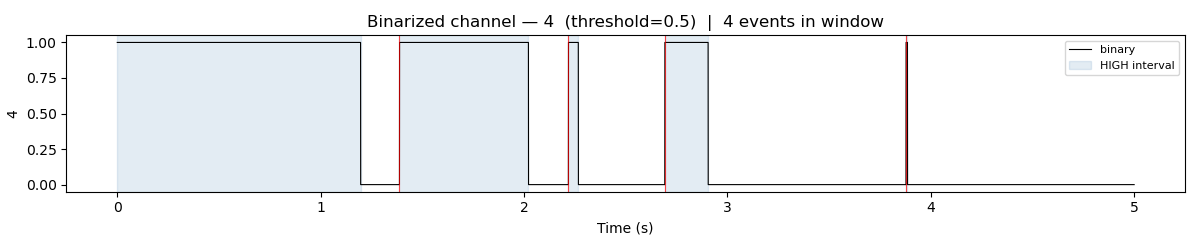

In [18]:
# ---- Visualise: binarized trace + detected events + shaded intervals (first 5 s) ----
t_plot_start = float(nidq_bin[DIM_TIME].values[0])
t_plot_end   = t_plot_start + 5.0

trace = nidq_bin.sel({DIM_TIME: slice(t_plot_start, t_plot_end), DIM_CHAN: digital_channel})
t_ax  = trace[DIM_TIME].values

fig, ax = plt.subplots(figsize=(12, 2.5))
ax.plot(t_ax, trace.values, color='black', lw=0.8, label='binary')

# Overlay rising-edge events
evt_in_win = dig_events.index[
    (dig_events.index >= t_plot_start) & (dig_events.index <= t_plot_end)
].values
for t_ev in evt_in_win:
    ax.axvline(t_ev, color='red', lw=0.8, alpha=0.7)

# Shade HIGH intervals
for _, row in dig_intervals.as_dataframe().iterrows():
    s, e = float(row['start']), float(row['end'])
    if e >= t_plot_start and s <= t_plot_end:
        ax.axvspan(max(s, t_plot_start), min(e, t_plot_end),
                   alpha=0.15, color='steelblue', label='HIGH interval')

ax.set_xlabel('Time (s)')
ax.set_ylabel(str(digital_channel))
ax.set_title(f'Binarized channel — {digital_channel}  (threshold={binary_threshold})  |  {len(evt_in_win)} events in window')
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()


## 5. Extract Analog Events and Intervals

- `analog_to_events()` detects threshold crossings on a continuous channel → `nap.Ts`
- `analog_to_intervals()` converts above-threshold periods → `nap.IntervalSet`
- The `hysteresis` parameter (volts) adds Schmitt-trigger noise rejection: the signal must fall `hysteresis` below `threshold` before a new rising event is detected
- `threshold` is expressed in whatever units the DataArray carries (V if gain-calibrated)

Set `analog_channel` and `analog_threshold` for your signal.

In [19]:
# ---- Parameters ----
# Select the first analog channel; replace with a channel id/label as needed
analog_channels = [
    ch for ch in nidq[DIM_CHAN].values
    if str(nidq.coords['chan_type'].sel({DIM_CHAN: ch}).values) == 'analog'
]
analog_channel   = analog_channels[0] if analog_channels else nidq[DIM_CHAN].values[0]
analog_threshold = 0.5   # volts — adjust to your signal
analog_hysteresis = 0.1  # volts — noise rejection band

# Rising-edge threshold crossings
analog_events = analog_to_events(
    nidq, channel=analog_channel,
    threshold=analog_threshold, edge='rising',
    hysteresis=analog_hysteresis,
)
print(f"Channel         : {analog_channel}")
print(f"Threshold       : {analog_threshold} {nidq.attrs.get(ATTR_UNITS, '')}")
print(f"Events (rising) : {len(analog_events)}")
if len(analog_events) > 0:
    print(f"First 5 (s)     : {analog_events.index[:5].values}")

# Above-threshold intervals
analog_intervals = analog_to_intervals(
    nidq, channel=analog_channel,
    threshold=analog_threshold, hysteresis=analog_hysteresis,
)
print(f"\nIntervals       : {len(analog_intervals)}")
print(analog_intervals[:5])

c:\Users\dbh60\.conda\envs\mimo_env2\lib\site-packages\pynapple\core\base_class.py:50: UserWarning: Some epochs have no duration
  self.time_support = IntervalSet(start=self.index[0], end=self.index[-1])
c:\Users\dbh60\.conda\envs\mimo_env2\lib\site-packages\pynapple\core\base_class.py:52: RuntimeWarning: divide by zero encountered in scalar divide
  self.rate = self.index.shape[0] / np.sum(


Channel         : 0
Threshold       : 0.5 V
Events (rising) : 1
First 5 (s)     : [0.]

Intervals       : 0
index    start    end
-------  -------  -----
shape: (0, 2), time unit: sec.


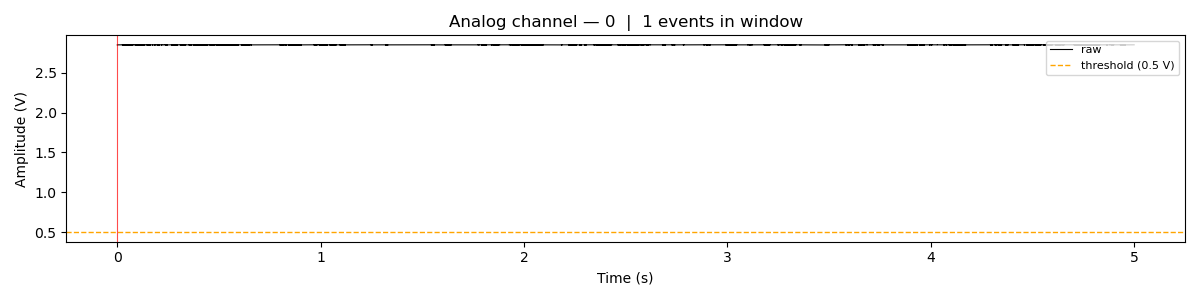

In [20]:
# ---- Visualise: raw trace + threshold + detected events + shaded intervals (first 5 s) ----
t_plot_start = float(nidq[DIM_TIME].values[0])
t_plot_end   = t_plot_start + 5.0

trace = nidq.sel({DIM_TIME: slice(t_plot_start, t_plot_end), DIM_CHAN: analog_channel})
t_ax  = trace[DIM_TIME].values
units = nidq.attrs.get(ATTR_UNITS, 'AU')

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_ax, trace.values, color='black', lw=0.8, label='raw')
ax.axhline(analog_threshold, color='orange', ls='--', lw=1.0, label=f'threshold ({analog_threshold} {units})')

# Overlay events
evt_in_win = analog_events.index[
    (analog_events.index >= t_plot_start) & (analog_events.index <= t_plot_end)
].values
for t_ev in evt_in_win:
    ax.axvline(t_ev, color='red', lw=0.8, alpha=0.7)

# Shade above-threshold intervals
for _, row in analog_intervals.as_dataframe().iterrows():
    s, e = float(row['start']), float(row['end'])
    if e >= t_plot_start and s <= t_plot_end:
        ax.axvspan(max(s, t_plot_start), min(e, t_plot_end),
                   alpha=0.15, color='steelblue', label='above threshold')

ax.set_xlabel('Time (s)')
ax.set_ylabel(f'Amplitude ({units})')
ax.set_title(f'Analog channel — {analog_channel}  |  {len(evt_in_win)} events in window')
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

## 6. Track Pulse Frequency

- `track_pulse_frequency()` computes the instantaneous pulse rate (Hz) on the original time grid.
- For a **digital channel** (`threshold=None`): uses inter-spike interval (ISI) of detected rising edges; values are NaN outside the first/last event.
- For an **analog channel**: first thresholds to events, then computes ISI.
- Pass `window` (seconds) for a sliding-window count instead of ISI (no NaN, returns 0 when no events in window).

In [22]:
# ---- Track frequency on the digital channel ----
freq = track_pulse_frequency(nidq_bin, channel=digital_channel)

print(f"Output shape : {freq.shape}  dims={freq.dims}")
print(f"Units        : {freq.attrs.get(ATTR_UNITS, '(not set)')}")
print(f"Non-NaN pts  : {int((~np.isnan(freq.values)).sum())} / {freq.sizes[DIM_TIME]}")

Output shape : (286160384,)  dims=('time',)
Units        : Hz
Non-NaN pts  : 286131750 / 286160384


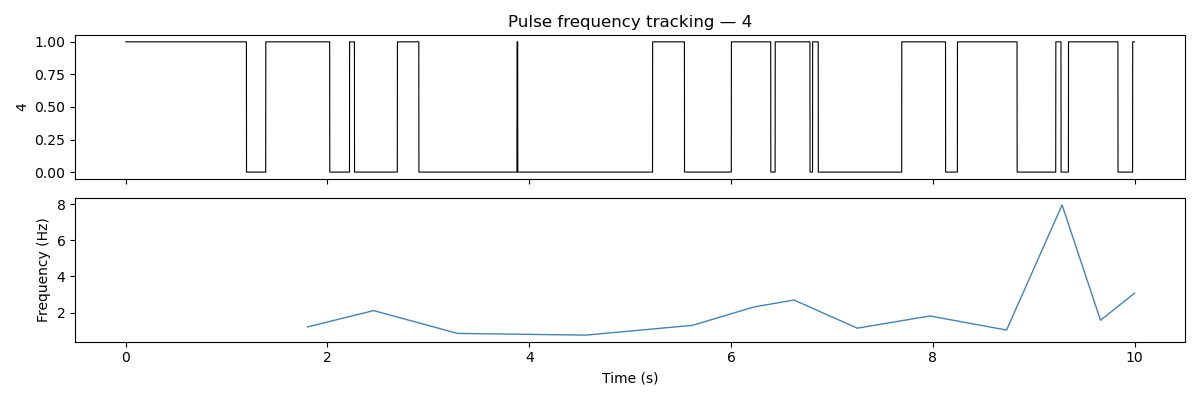

In [23]:
# ---- Visualise: binarized trace (top) + instantaneous frequency (bottom) ----
t_plot_start = float(nidq_bin[DIM_TIME].values[0])
t_plot_end   = t_plot_start + 10.0

trace = nidq_bin.sel({DIM_TIME: slice(t_plot_start, t_plot_end), DIM_CHAN: digital_channel})
freq_win = freq.sel({DIM_TIME: slice(t_plot_start, t_plot_end)})

fig, axes = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
axes[0].plot(trace[DIM_TIME].values, trace.values, color='black', lw=0.8)
axes[0].set_ylabel(str(digital_channel))
axes[0].set_title(f'Pulse frequency tracking — {digital_channel}')

axes[1].plot(freq_win[DIM_TIME].values, freq_win.values, color='steelblue', lw=1.0)
axes[1].set_ylabel(f"Frequency ({freq.attrs.get(ATTR_UNITS, 'Hz')})")
axes[1].set_xlabel('Time (s)')

plt.tight_layout()
plt.show()

## 7. Pulse Statistics and Bout Detection

- `pulse_stats()` returns a `nap.IntervalSet` with onset/offset times and per-pulse metadata columns: `duration`, `isi`, `bout_id`, `pulse_in_bout`. Bouts are defined by an ISI exceeding 2× the median ISI.
- `detect_bouts()` groups any `nap.Ts` object into bouts separated by a specified gap threshold, returning a `nap.IntervalSet` of bout start/end times.

In [24]:
# Per-pulse statistics
stats_iset = pulse_stats(nidq_bin, channel=digital_channel)

print(f"Pulses detected : {len(stats_iset)}")
stats_df = stats_iset.as_dataframe()
print("\nFirst 10 pulses:")
stats_df.head(10)

Pulses detected : 33689

First 10 pulses:


,start,end,duration,isi,bout_id,pulse_in_bout
0,0.000000,1.196426,1.196426,1.387680,0,0
1,1.387680,2.021765,0.634085,0.830531,1,0
2,2.218211,2.267016,0.048805,0.473982,1,1
3,2.692194,2.905254,0.213061,1.185947,1,2
4,3.878141,3.885410,0.007269,1.343973,1,3
5,5.222114,5.538070,0.315957,0.780594,1,4
6,6.002707,6.393523,0.390816,0.434429,1,5
7,6.437136,6.782262,0.345126,0.371086,1,6
8,6.808222,6.864390,0.056168,0.883490,1,7
9,7.691712,8.126235,0.434523,0.551957,1,8


In [25]:
# ---- Parameters ----
bout_gap_threshold = 1.0   # seconds — gaps larger than this separate bouts

bouts = detect_bouts(dig_events, gap_threshold=bout_gap_threshold)

print(f"Bouts detected  : {len(bouts)}")
bouts_df = bouts.as_dataframe()
bouts_df['duration'] = bouts_df['end'] - bouts_df['start']
print(f"Bout duration   : mean={bouts_df['duration'].mean():.3f} s  "
      f"min={bouts_df['duration'].min():.3f} s  max={bouts_df['duration'].max():.3f} s")

# Pulses per bout summary
if 'bout_id' in stats_df.columns:
    pulses_per_bout = stats_df.groupby('bout_id').size().rename('pulses')
    print(f"\nPulses per bout: mean={pulses_per_bout.mean():.1f}  "
          f"min={pulses_per_bout.min()}  max={pulses_per_bout.max()}")

Bouts detected  : 9737
Bout duration   : mean=1.261 s  min=0.000 s  max=12.818 s

Pulses per bout: mean=6.6  min=1  max=51


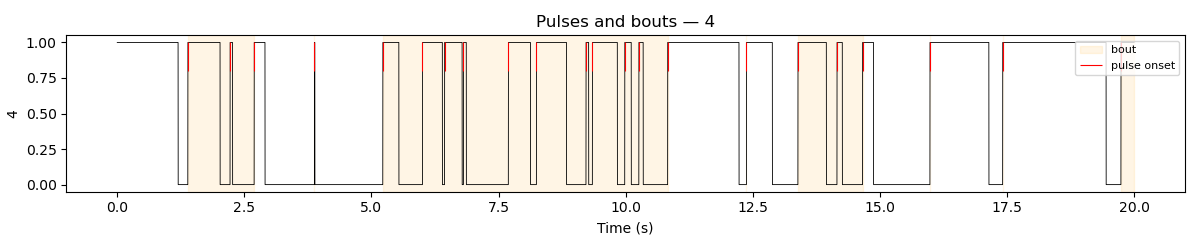

In [26]:
# ---- Visualise: binarized trace + bout regions + individual pulse ticks (first 20 s) ----
t_plot_start = float(nidq_bin[DIM_TIME].values[0])
t_plot_end   = t_plot_start + 20.0

trace = nidq_bin.sel({DIM_TIME: slice(t_plot_start, t_plot_end), DIM_CHAN: digital_channel})

fig, ax = plt.subplots(figsize=(12, 2.5))
ax.plot(trace[DIM_TIME].values, trace.values, color='black', lw=0.6, zorder=3)

# Shade bout regions
for _, row in bouts_df.iterrows():
    s, e = float(row['start']), float(row['end'])
    if e >= t_plot_start and s <= t_plot_end:
        ax.axvspan(max(s, t_plot_start), min(e, t_plot_end),
                   alpha=0.1, color='orange', zorder=1, label='bout')

# Individual pulse onset ticks
evt_in_win = dig_events.index[
    (dig_events.index >= t_plot_start) & (dig_events.index <= t_plot_end)
].values
ax.vlines(evt_in_win, ymin=0.8, ymax=1.0, color='red', lw=0.8, zorder=4, label='pulse onset')

ax.set_xlabel('Time (s)')
ax.set_ylabel(str(digital_channel))
ax.set_title(f'Pulses and bouts — {digital_channel}')
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

## 8. Batch Event Extraction

`extract_nidq_events()` reads the channel configuration saved by the widget (§2) and dispatches the appropriate extraction function for each channel:

| Channel type | Extracted objects |
|---|---|
| `'digital'` or `'ttl'` | `{label}.events` (`nap.Ts`) + `{label}.intervals` (`nap.IntervalSet`) |
| `'sync'` | `{label}.events` (`nap.Ts`) only |
| `'analog'` | `{label}.events` + `{label}.intervals`  (requires `threshold` in config) |
| `'other'` | skipped |

The returned dict keys follow the pattern `"{label}.events"` and `"{label}.intervals"`.

In [27]:
# Read saved channel config and convert to the list format expected by extract_nidq_events
sess_fresh2 = Session(initializer.session.dir)
saved_channels = sess_fresh2.config.get('parameters', {}).get('nidq_channels', {})

if not saved_channels:
    print("No channel config saved — run the widget (§2) and click 'Save to Config' first.")
else:
    # extract_nidq_events expects a list of dicts: [{channel, label, type, (threshold)}, ...]
    channel_config = [
        {'channel': cid, **cfg}
        for cid, cfg in saved_channels.items()
    ]

    results = extract_nidq_events(nidq, channel_config)

    print(f"Extracted {len(results)} objects:\n")
    for key, val in results.items():
        type_str = type(val).__name__
        if hasattr(val, '__len__'):
            print(f"  {key:<35s}  {type_str}  (n={len(val)})")
        else:
            print(f"  {key:<35s}  {type_str}")


No channel config saved — run the widget (§2) and click 'Save to Config' first.
